<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/12_pca_imputed_ansel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCA on the design attributes by decade, rerun on imputed rows instead of dropped rows

Notebook 03 ran a PCA on seven numeric design attributes (minimum and maximum players, minimum and maximum play time, minimum age, number of mechanics, number of categories) for games published in the 1970s through the 2020s, and dropped every game with any of the seven missing. Notebook 05 showed that the games with a missing input are not a random subset: they rate lower and have fewer raters. This notebook keeps those games, fills in their missing attributes, reruns notebook 03's PCA, and compares the two side by side.

Choices made for this notebook:

| Choice | Setting | Why |
| --- | --- | --- |
| Rows | games from the 1970s to the 2020s, minus the 55 missing 4 or more of the 8 inputs (20,928) | the same row rule as notebook 05: the 195 games with no year stay out (they also cannot be placed in a decade, as in notebook 03), and so do games missing 4 or more inputs, because most of their row would be invented |
| Imputer | `KNNImputer(n_neighbors=5)` on standardized inputs | fills a gap with the average of the 5 most similar games, which keeps the correlations between attributes that the PCA reads; a median fill would pile values at the centre and weaken them. Notebook 05 chose a plain median fill for prediction, where the five imputers it tested tied; here the attributes themselves are analysed, so an imputer that keeps their correlations matters more than for a prediction |
| Imputer inputs | the seven attributes (log scale where notebook 03 uses it) plus `yearpublished` | year makes the neighbours come from the same era, so a filled value does not pull a game towards the all-decade average; year is dropped again before the PCA |
| PCA | identical to notebook 03 | log10 of player counts and play times, standardize, seven components, loadings as correlations |

No train/test split is needed: this is a descriptive analysis, as in notebook 03.

In [1]:
# --- Ansel Weng: rerun notebook 03's PCA by decade on k-NN-imputed rows and compare with the dropped-row version ---
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Every code and markdown cell in this notebook was generated with Claude Code from notebooks 03 and 05; reviewed and edited by Ansel Weng.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.decomposition import PCA

## 1. Load and scope

In [2]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Same loading cell as notebooks 02 to 05; reviewed and edited by Ansel Weng.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

(21631, 24)


In [3]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Figure folder helper, as in notebooks 03 and 05; reviewed and edited by Ansel Weng.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

In [4]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-11. The seven attributes and the scope; games from the 1970s on, minus those notebook 05's row rule drops (4 or more of the 8 inputs missing); a flag marks the ones notebook 03 dropped; reviewed and edited by Ansel Weng.
attrs = ["minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
log_cols = ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]
in_decades = games[games["decade"] >= 1970].copy()
# Notebook 05's row rule: drop games with no year (already out, since they have no decade) and games missing 4 or more of
# the 8 inputs (year plus these seven). Every game here has a year, so that is 4 or more of the seven attributes.
too_sparse = in_decades[["yearpublished"] + attrs].isna().sum(axis=1) >= 4
print("games 1970s to 2020s:", len(in_decades), "| missing 4+ of 8 inputs, dropped by notebook 05's rule:", int(too_sparse.sum()))
scope = in_decades[~too_sparse].copy()
scope["decade"] = scope["decade"].astype(int).astype(str) + "s"
scope["complete"] = scope[attrs].notna().all(axis=1)
print("games kept:", len(scope), "| all seven known (notebook 03's rows):", scope["complete"].sum(),
      "| at least one missing (imputed here):", (~scope["complete"]).sum())
scope[attrs].isna().sum().to_frame("games missing").assign(**{"share missing (%)": lambda t: (100 * t["games missing"] / len(scope)).round(2)})

games 1970s to 2020s: 20983 | missing 4+ of 8 inputs, dropped by notebook 05's rule: 55
games kept: 20928 | all seven known (notebook 03's rows): 17636 | at least one missing (imputed here): 3292


,games missing,share missing (%)
minplayers,16,0.08
maxplayers,115,0.55
minplaytime,545,2.60
maxplaytime,676,3.23
minage,1177,5.62
n_mechanics,1461,6.98
n_categories,266,1.27


In [5]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. How many attributes each incomplete game is missing, and how the dropped games are spread across decades; reviewed and edited by Ansel Weng.
print("attributes missing per game:", scope[attrs].isna().sum(axis=1).value_counts().sort_index().to_dict())
by_decade = scope.groupby("decade").agg(games=("complete", "size"), complete=("complete", "sum"))
by_decade["dropped in notebook 03"] = by_decade["games"] - by_decade["complete"]
by_decade["share dropped (%)"] = (100 * by_decade["dropped in notebook 03"] / by_decade["games"]).round(1)
by_decade

attributes missing per game: {0: 17636, 1: 2560, 2: 500, 3: 232}


,games,complete,dropped in notebook 03,share dropped (%)
decade,,,,
1970s,789,676,113,14.3
1980s,1318,1139,179,13.6
1990s,2052,1643,409,19.9
2000s,4627,3676,951,20.6
2010s,10456,9009,1447,13.8
2020s,1686,1493,193,11.4


**Takeaway:** notebook 05's row rule removes 55 of the 20,983 games from the 1970s on, each missing 4 or more inputs. Of the 20,928 kept, 3,292 (15.7%) have at least one of the seven attributes missing, most often the number of mechanics (1,461 games) and minimum age (1,177). Most of them lack a single attribute (2,560 games); 232 lack three, and none more. The incomplete games are not spread evenly over time: notebook 03 lost about 20% of the 1990s and 2000s (409 and 951 of the games kept here) but only 11 to 14% of the other decades, so dropping them under-represents those two decades in particular.

## 2. Fill in the missing attributes with the k-NN imputer

The four long-tailed attributes go on the log10 scale first, exactly as in notebook 03, so that "similar" means similar on the scale the PCA uses. All eight imputer inputs are standardized, because `KNNImputer` measures distance in raw units and minimum age would otherwise dominate (notebook 03, section 2). `StandardScaler` ignores missing cells when it computes means and standard deviations and leaves them missing. After filling, the scaling is undone so the attributes are back on their log10 or count scale.

In [6]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Log-transform, standardize, k-NN impute with year as a helper, undo the scaling; reviewed and edited by Ansel Weng.
def to_log(frame):
    X = frame[attrs].copy()
    for col in log_cols:
        X[col] = np.log10(X[col])          # log10 of a missing value stays missing
    return X.rename(columns={col: "log10_" + col for col in log_cols})

X_obs = to_log(scope)                                       # seven PCA attributes, with the gaps
imp_inputs = pd.concat([scope[["yearpublished"]], X_obs], axis=1)
imp_scaler = StandardScaler()
imp_scaled = imp_scaler.fit_transform(imp_inputs)          # gaps stay missing
filled_scaled = KNNImputer(n_neighbors=5).fit_transform(imp_scaled)
filled = pd.DataFrame(imp_scaler.inverse_transform(filled_scaled), columns=imp_inputs.columns, index=scope.index)

X_imp = filled[X_obs.columns]                               # year is dropped again before the PCA
observed = X_obs.notna()
assert np.allclose(X_imp.values[observed.values], X_obs.values[observed.values]), "observed values must not change"
assert X_imp.notna().all().all()
print("cells filled:", int((~observed).sum().sum()), "in", (~scope["complete"]).sum(), "games")

cells filled: 4256 in 3292 games


In [7]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Filled-in values against observed values, attribute by attribute, on the PCA's scale; reviewed and edited by Ansel Weng.
check = pd.DataFrame({
    "filled cells": (~observed).sum(),
    "observed mean": X_obs.mean(),
    "filled mean": X_imp[~observed].mean(),
    "observed sd": X_obs.std(),
    "filled sd": X_imp[~observed].std(),
})
check.round(2)

,filled cells,observed mean,filled mean,observed sd,filled sd
log10_minplayers,16,0.28,0.24,0.15,0.06
log10_maxplayers,115,0.63,0.67,0.26,0.27
log10_minplaytime,545,1.59,1.58,0.40,0.31
log10_maxplaytime,676,1.69,1.66,0.41,0.32
minage,1177,10.28,10.30,2.78,1.77
n_mechanics,1461,3.16,2.23,2.12,0.82
n_categories,266,2.67,2.32,1.35,0.68


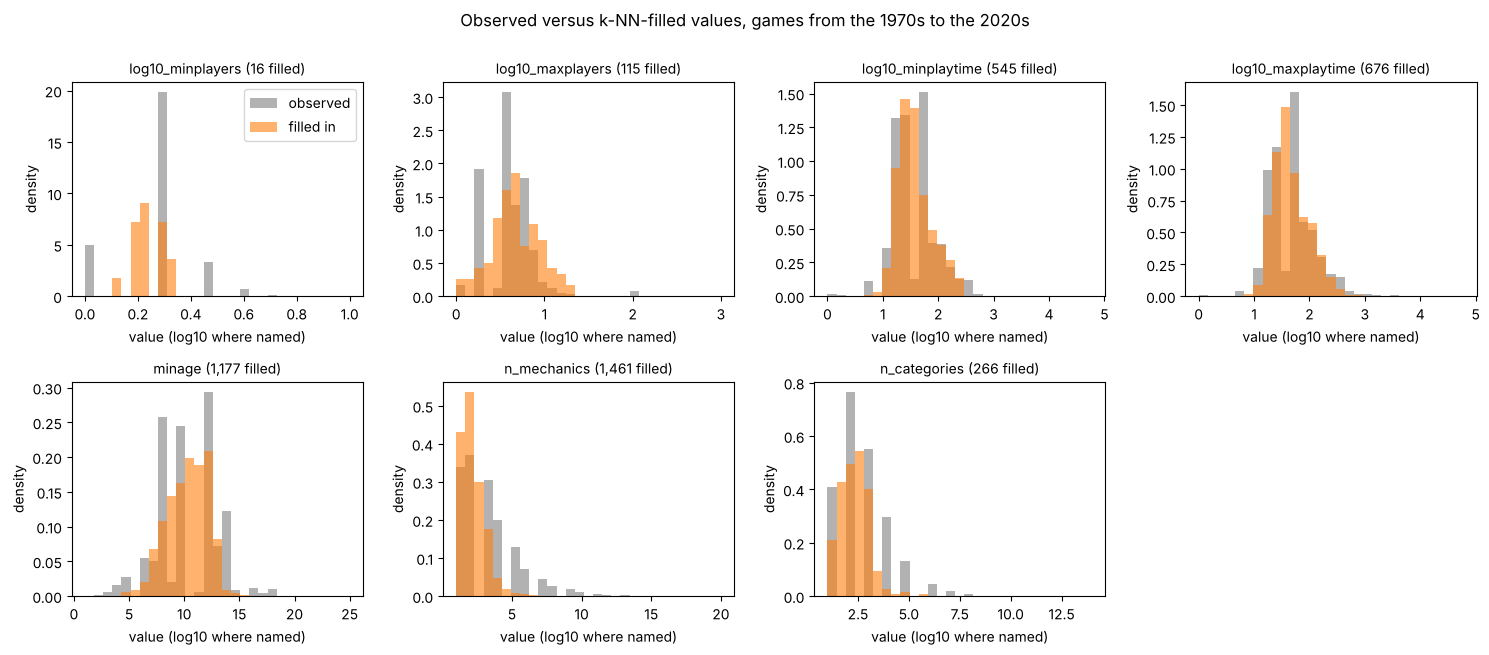

In [8]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Distribution of observed and filled-in values for each attribute; reviewed and edited by Ansel Weng.
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.ravel(), X_obs.columns):
    bins = np.linspace(X_obs[col].min(), X_obs[col].max(), 30)
    ax.hist(X_obs[col].dropna(), bins=bins, density=True, alpha=0.6, color="0.5", label="observed")
    ax.hist(X_imp.loc[~observed[col], col], bins=bins, density=True, alpha=0.6, color="tab:orange", label="filled in")
    ax.set_title(f"{col} ({(~observed[col]).sum():,} filled)", fontsize=10)
    ax.set_xlabel("value (log10 where named)")
    ax.set_ylabel("density")
axes.ravel()[0].legend()
axes.ravel()[-1].axis("off")
fig.suptitle("Observed versus k-NN-filled values, games from the 1970s to the 2020s", y=1.0)
plt.tight_layout()
save("12_imputed_vs_observed.png")
plt.show()

**Takeaway:** 4,256 cells are filled in across the 3,292 games, and every observed value is unchanged (checked by the `assert`). For player counts, play times and minimum age, the filled-in values have nearly the same mean as the observed ones (minimum age 10.30 filled against 10.28 observed). The exception is the number of mechanics: filled-in games average 2.23 mechanics against 3.16 for games with a list, and 2.32 against 2.67 categories. Their nearest neighbours by year, play time, age and player count are games with short lists, which fits notebook 05's finding that games with missing information are the less-catalogued ones. Filled-in values are less spread out than observed ones (standard deviation 0.82 against 2.12 mechanics), because each is an average of five neighbours. That shrinkage is much smaller than a single median value would give, but it is the reason imputed rows can only nudge, not reshape, the PCA.

In [9]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-11. Games whose minimum play time ends up above their maximum, in the raw data and after the k-NN fill; reviewed and edited by Ansel Weng.
min_pt, max_pt = X_imp["log10_minplaytime"], X_imp["log10_maxplaytime"]
above_after = min_pt > max_pt + 1e-9                          # tolerance: equal values can differ in the last digit after the log round trip
above_raw = scope["minplaytime"] > scope["maxplaytime"]
print("minimum play time above maximum: raw data", int(above_raw.sum()), "| after the fill", int(above_after.sum()),
      "| created by the fill", int((above_after & ~above_raw).sum()))
print("minimum players above maximum after the fill:", int((X_imp["log10_minplayers"] > X_imp["log10_maxplayers"] + 1e-9).sum()))


minimum play time above maximum: raw data 4 | after the fill 47 | created by the fill 43
minimum players above maximum after the fill: 0


**Takeaway:** the imputer fills each attribute on its own, so it can break a rule that holds between two attributes. Here that happens for play time only: after the fill, 47 games have a minimum play time above their maximum, 43 of them created by the fill (4 are like that in the raw data). That is 0.2% of the 20,928 games, too few to move a loading or a decade median, but those 47 rows are not real games. No game ends up with more minimum than maximum players.

## 3. Fit the same PCA on both sets of rows

One function does notebook 03's steps (standardize, fit seven components, eigenvalue table, loadings as correlations), so the only thing that differs between the two runs is the rows. The **dropped** run uses the 17,636 complete games and reproduces notebook 03; the **imputed** run uses all 20,928 kept games.

The sign of a component is arbitrary (notebook 03, section 7). To make the two runs readable side by side, an imputed component is flipped when its loadings point the opposite way from the dropped run's.

In [10]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. The PCA from notebook 03 as one function, run on the dropped rows and on the imputed rows; reviewed and edited by Ansel Weng.
pc_names = ["PC" + str(i + 1) for i in range(7)]

def run_pca(X):
    scaler = StandardScaler()
    Z = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
    pca = PCA(n_components=7).fit(Z)
    scores = pd.DataFrame(pca.transform(Z), columns=pc_names, index=X.index)
    loadings = pd.concat([scores, Z], axis=1).corr().loc[Z.columns, pc_names]
    summary = pd.DataFrame({
        "Eigenvalue": pca.explained_variance_,
        "% of variance": pca.explained_variance_ratio_ * 100,
        "Cumulative %": np.cumsum(pca.explained_variance_ratio_) * 100,
    }, index=pc_names)
    return {"X": X, "scaler": scaler, "pca": pca, "scores": scores, "loadings": loadings, "summary": summary}

drop = run_pca(X_obs[scope["complete"]])
imp = run_pca(X_imp)

# Flip imputed components whose loadings point the other way from the dropped run's.
flips = []
for pc in pc_names:
    if np.corrcoef(drop["loadings"][pc], imp["loadings"][pc])[0, 1] < 0:
        imp["scores"][pc] *= -1
        imp["loadings"][pc] *= -1
        flips.append(pc)
print("rows:", len(drop["X"]), "dropped run |", len(imp["X"]), "imputed run | imputed components flipped:", flips or "none")

rows: 17636 dropped run | 20928 imputed run | imputed components flipped: none


## 4. Variance explained

In [11]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Eigenvalue table for both runs side by side; reviewed and edited by Ansel Weng.
variance = pd.concat({"dropped (notebook 03)": drop["summary"], "imputed": imp["summary"]}, axis=1)
variance.round(2)

dropped (notebook 03)                               imputed                \
               Eigenvalue % of variance Cumulative % Eigenvalue % of variance   
PC1                  2.52         36.03        36.03       2.52         36.05   
PC2                  1.22         17.43        53.46       1.24         17.66   
PC3                  1.19         17.03        70.49       1.19         16.96   
PC4                  0.73         10.43        80.92       0.72         10.27   
PC5                  0.63          8.94        89.86       0.63          8.94   
PC6                  0.60          8.50        98.36       0.59          8.47   
PC7                  0.11          1.64       100.00       0.11          1.63   

                  
    Cumulative %  
PC1        36.05  
PC2        53.71  
PC3        70.68  
PC4        80.95  
PC5        89.89  
PC6        98.37  
PC7       100.00

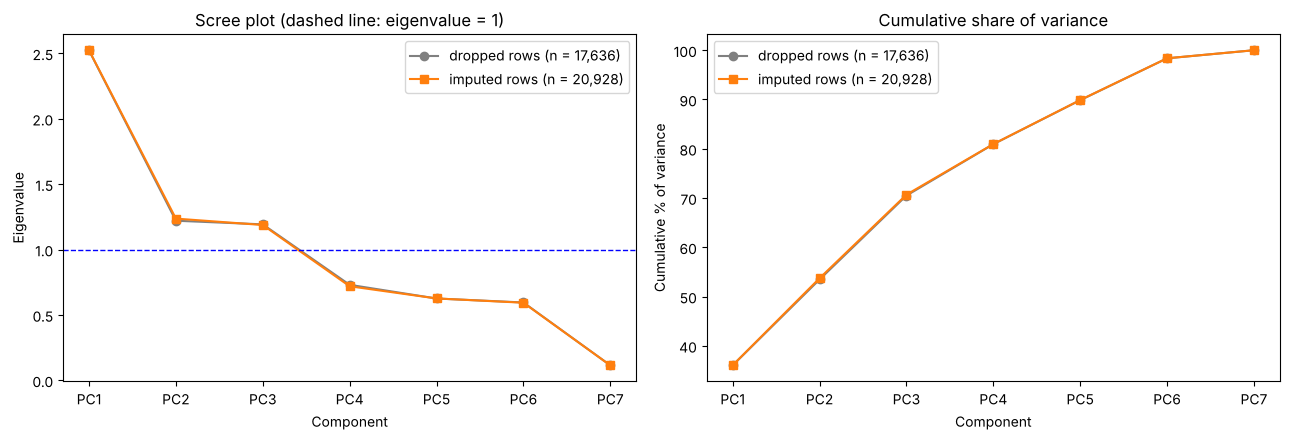

In [12]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Scree plot and cumulative variance for both runs on the same axes; reviewed and edited by Ansel Weng.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for run, style, colour in [(drop, "o-", "0.5"), (imp, "s-", "tab:orange")]:
    label = "dropped rows (n = {:,})".format(len(run["X"])) if run is drop else "imputed rows (n = {:,})".format(len(run["X"]))
    axes[0].plot(pc_names, run["summary"]["Eigenvalue"], style, color=colour, label=label)
    axes[1].plot(pc_names, run["summary"]["Cumulative %"], style, color=colour, label=label)
axes[0].axhline(1, color="b", linestyle="--", linewidth=1)
axes[0].set_title("Scree plot (dashed line: eigenvalue = 1)")
axes[0].set_xlabel("Component")
axes[0].set_ylabel("Eigenvalue")
axes[1].set_title("Cumulative share of variance")
axes[1].set_xlabel("Component")
axes[1].set_ylabel("Cumulative % of variance")
for ax in axes:
    ax.legend()
plt.tight_layout()
save("12_scree_compare.png")
plt.show()

**Takeaway:** the dropped run reproduces notebook 03 exactly (eigenvalues 2.52, 1.22, 1.19; 70.49% from three components). On the imputed rows the variance table hardly moves: the same three components have eigenvalues above 1 (2.52, 1.24, 1.19) and carry 70.68%, two carry 53.71% and four 80.95%. No component changes its share by more than 0.23 percentage points, and the scree plot still bends after the third component.

## 5. Correlations and loadings

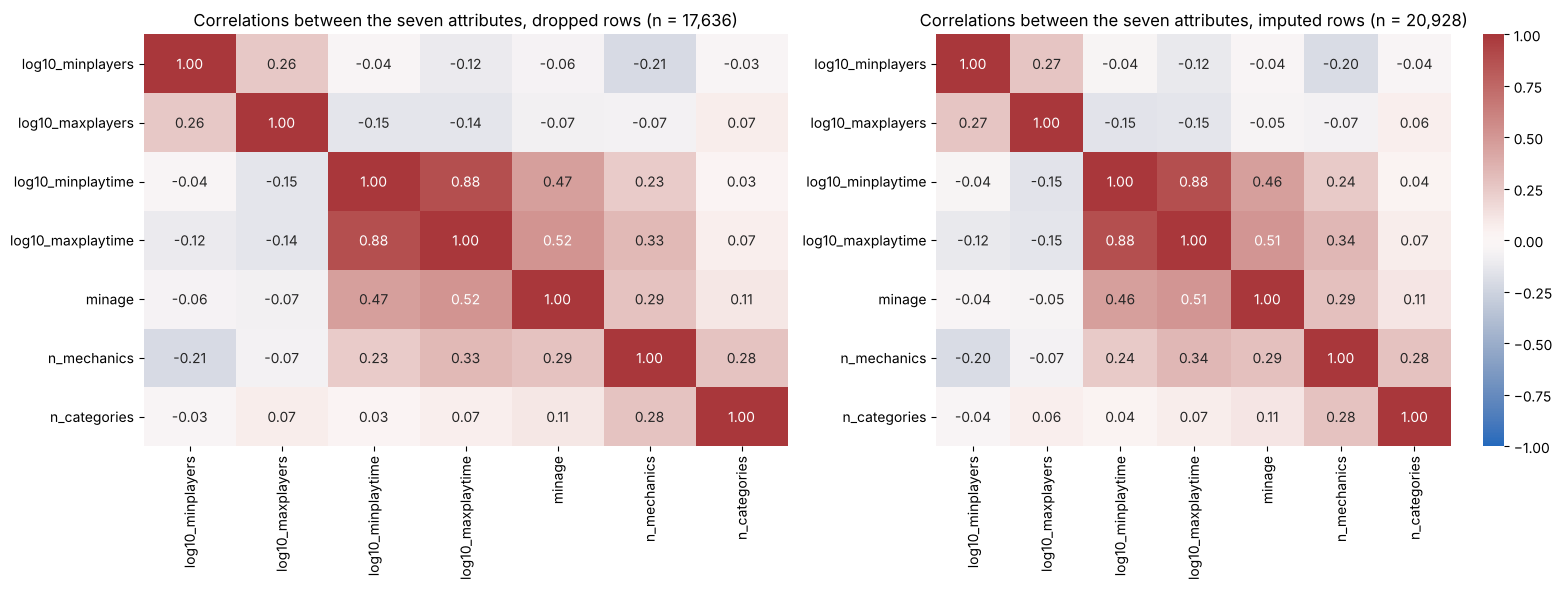

largest change in any correlation: 0.02


In [13]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Correlations between the seven attributes, dropped rows against imputed rows; reviewed and edited by Ansel Weng.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, run, title in [(axes[0], drop, "dropped rows"), (axes[1], imp, "imputed rows")]:
    sns.heatmap(run["X"].corr(), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=ax, cbar=ax is axes[1])
    ax.set_title(f"Correlations between the seven attributes, {title} (n = {len(run['X']):,})")
plt.tight_layout()
save("12_attribute_correlations_compare.png")
plt.show()
corr_change = imp["X"].corr() - drop["X"].corr()
print("largest change in any correlation:", round(corr_change.abs().values.max(), 3))

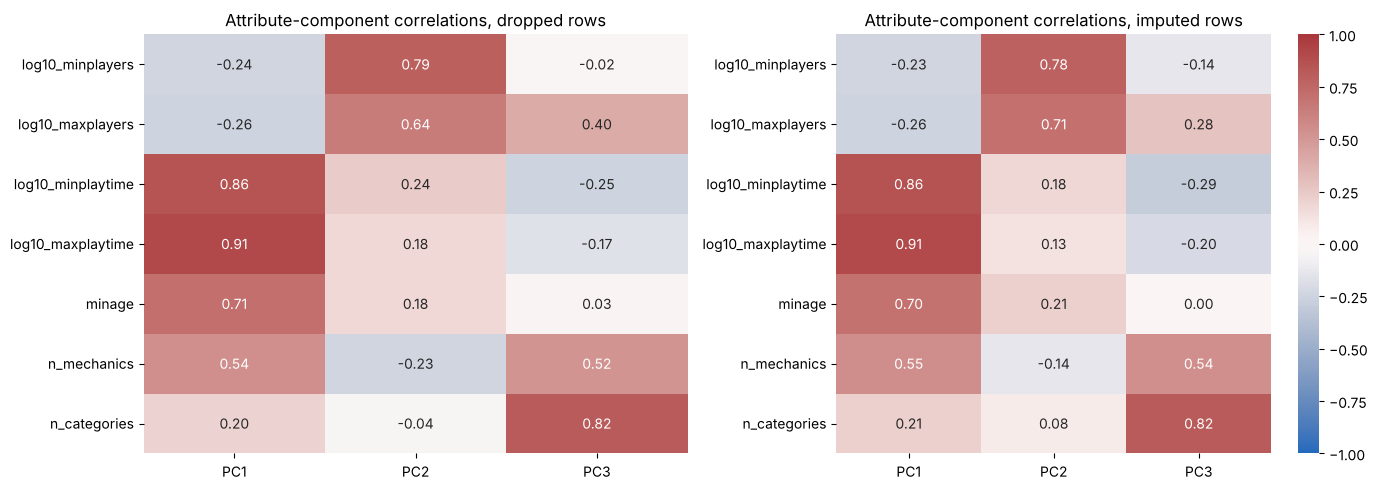

dropped             imputed             imputed - dropped  \
                      PC1   PC2   PC3     PC1   PC2   PC3               PC1   
log10_minplayers    -0.24  0.79 -0.02   -0.23  0.78 -0.14              0.01   
log10_maxplayers    -0.26  0.64  0.40   -0.26  0.71  0.28             -0.00   
log10_minplaytime    0.86  0.24 -0.25    0.86  0.18 -0.29              0.00   
log10_maxplaytime    0.91  0.18 -0.17    0.91  0.13 -0.20             -0.00   
minage               0.71  0.18  0.03    0.70  0.21  0.00             -0.01   
n_mechanics          0.54 -0.23  0.52    0.55 -0.14  0.54              0.01   
n_categories         0.20 -0.04  0.82    0.21  0.08  0.82              0.01   

                               
                    PC2   PC3  
log10_minplayers  -0.01 -0.12  
log10_maxplayers   0.07 -0.12  
log10_minplaytime -0.06 -0.04  
log10_maxplaytime -0.05 -0.04  
minage             0.04 -0.03  
n_mechanics        0.10  0.03  
n_categories       0.12 -0.00

In [14]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Loadings on the first three components for both runs, and the difference; reviewed and edited by Ansel Weng.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, run, title in [(axes[0], drop, "dropped rows"), (axes[1], imp, "imputed rows")]:
    sns.heatmap(run["loadings"][["PC1", "PC2", "PC3"]], annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=ax, cbar=ax is axes[1])
    ax.set_title(f"Attribute-component correlations, {title}")
plt.tight_layout()
save("12_loadings_compare.png")
plt.show()
loadings_side = pd.concat({"dropped": drop["loadings"][["PC1", "PC2", "PC3"]], "imputed": imp["loadings"][["PC1", "PC2", "PC3"]],
                           "imputed - dropped": (imp["loadings"] - drop["loadings"])[["PC1", "PC2", "PC3"]]}, axis=1)
loadings_side.round(2)

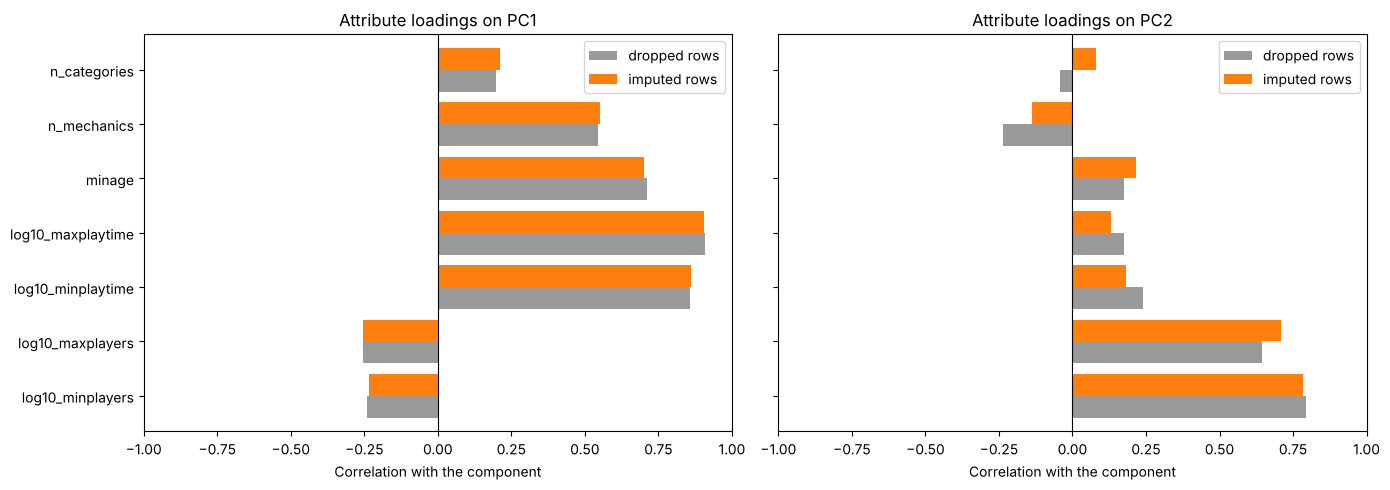

In [15]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. PC1 and PC2 loadings as paired bars; reviewed and edited by Ansel Weng.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, pc in zip(axes, ["PC1", "PC2"]):
    pd.DataFrame({"dropped rows": drop["loadings"][pc], "imputed rows": imp["loadings"][pc]}).plot.barh(ax=ax, width=0.8, color=["0.6", "tab:orange"])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-1, 1)
    ax.set_xlabel("Correlation with the component")
    ax.set_title(f"Attribute loadings on {pc}")
plt.tight_layout()
save("12_loadings_bars_compare.png")
plt.show()

**Takeaway:** no correlation between two attributes changes by more than 0.02, and **PC1 reads the same**: 0.91 with maximum play time, 0.86 with minimum play time, 0.70 with minimum age and 0.55 with the number of mechanics, every loading within 0.01 of notebook 03. PC2 is still the player-count component (0.78 with minimum and 0.71 with maximum players); the mechanics and categories loadings on it move by 0.10 and 0.12 but stay small (-0.14 and 0.08). PC3 is still the number of categories (0.82) and mechanics (0.54), with maximum players weaker (0.28 against 0.40). Minimum players also moves onto PC3, from -0.02 to -0.14: still small, but the largest change in any PC3 loading after maximum players. No component needed a sign flip. The names notebook 03 gave the components carry over unchanged.

## 6. The same analysis without scaling, on the imputed rows

Notebook 03's check that scaling matters, repeated on the imputed rows.

In [16]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Unscaled PCA on the imputed rows, as in notebook 03 section 5; reviewed and edited by Ansel Weng.
pcs_raw = PCA(n_components=7).fit(X_imp)
raw_summary = pd.DataFrame({"% of variance": pcs_raw.explained_variance_ratio_ * 100,
                            "Cumulative %": np.cumsum(pcs_raw.explained_variance_ratio_) * 100}, index=pc_names).round(1)
weights_raw = pd.DataFrame(pcs_raw.components_[:2].T, index=X_imp.columns, columns=["PC1 weight", "PC2 weight"]).round(2)
display(raw_summary.head(3))
weights_raw

,% of variance,Cumulative %
PC1,59.6,59.6
PC2,26.8,86.4
PC3,11.3,97.7


,PC1 weight,PC2 weight
log10_minplayers,-0.00,-0.01
log10_maxplayers,-0.01,-0.00
log10_minplaytime,0.07,-0.01
log10_maxplaytime,0.08,0.01
minage,0.91,-0.41
n_mechanics,0.40,0.87
n_categories,0.11,0.27


**Takeaway:** as in notebook 03, without scaling the first component follows the attribute with the largest spread (weight 0.91 on minimum age, 0.40 on mechanics; 59.6% of the variance against 58.7% in notebook 03). The scaled version is the one compared from here on.

## 7. Where each decade sits, dropped rows against imputed rows

Each run is read on its own components. Because the loadings barely move (section 5), the two sets of axes mean nearly the same thing, so the decade medians can be read against each other. As a check, the imputed rows are also projected onto the **dropped run's** components (its scaler and PCA): that holds the axes fixed and isolates the effect of adding the 3,292 incomplete games back.

In [17]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Decade medians on PC1 and PC2 for both runs, plus the imputed rows on the dropped run's axes; reviewed and edited by Ansel Weng.
decade = scope["decade"]
centres_drop = drop["scores"].groupby(decade[drop["scores"].index])[["PC1", "PC2"]].median()
centres_imp = imp["scores"].groupby(decade)[["PC1", "PC2"]].median()
Z_fixed = pd.DataFrame(drop["scaler"].transform(X_imp), columns=X_imp.columns, index=X_imp.index)
on_drop_axes = pd.DataFrame(drop["pca"].transform(Z_fixed), columns=pc_names, index=X_imp.index)
centres_fixed = on_drop_axes.groupby(decade)[["PC1", "PC2"]].median()
centres = pd.concat({"dropped (notebook 03)": centres_drop, "imputed, own axes": centres_imp,
                     "imputed, dropped run's axes": centres_fixed}, axis=1)
centres.round(2)

dropped (notebook 03)       imputed, own axes        \
                         PC1   PC2               PC1   PC2   
decade                                                       
1970s                   1.22 -0.12              0.89 -0.26   
1980s                   0.81  0.12              0.69 -0.03   
1990s                   0.15  0.30              0.14  0.15   
2000s                  -0.30  0.20             -0.34  0.11   
2010s                  -0.24 -0.02             -0.23 -0.04   
2020s                   0.36 -0.67              0.35 -0.57   

       imputed, dropped run's axes        
                               PC1   PC2  
decade                                    
1970s                         0.85 -0.13  
1980s                         0.62  0.13  
1990s                         0.09  0.30  
2000s                        -0.40  0.17  
2010s                        -0.30 -0.03  
2020s                         0.28 -0.60

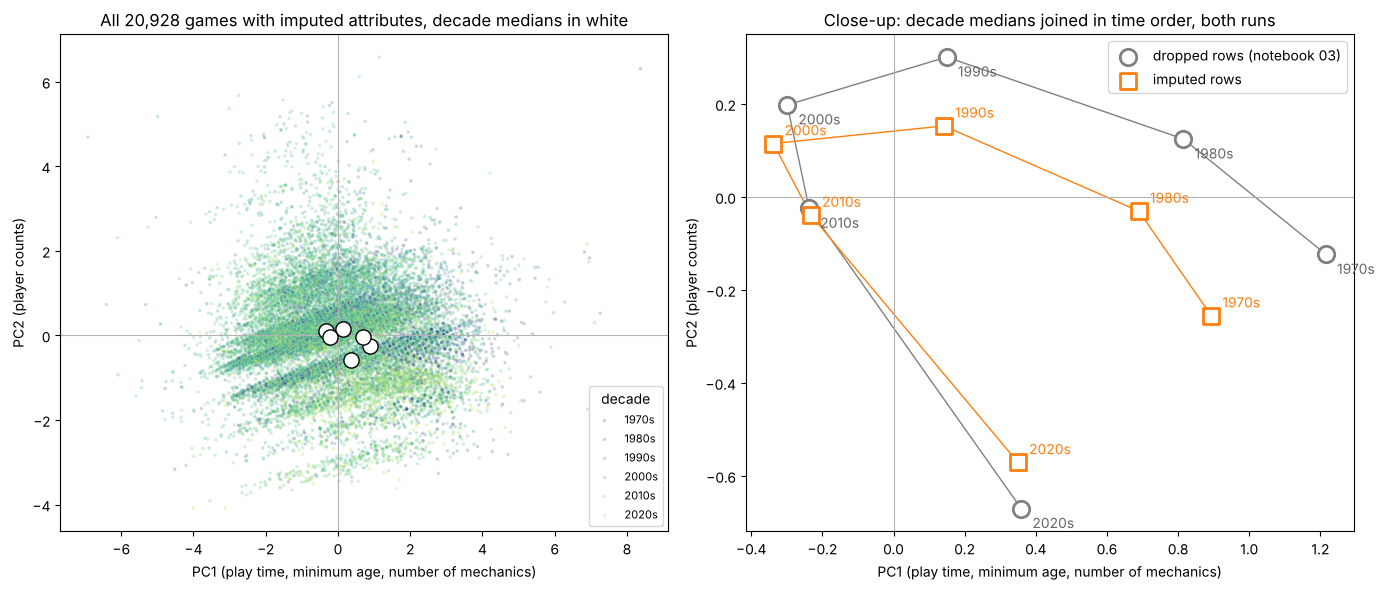

In [18]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Every game on the imputed run's PC1 and PC2 (left), and the decade-median paths of both runs (right); reviewed and edited by Ansel Weng.
plot_df = pd.concat([scope[["decade", "complete"]], imp["scores"][["PC1", "PC2"]]], axis=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="decade", hue_order=sorted(plot_df["decade"].unique()), s=6, alpha=0.25, palette="viridis", ax=axes[0])
axes[0].scatter(centres_imp["PC1"], centres_imp["PC2"], s=120, c="white", edgecolor="black", zorder=3)
axes[0].axhline(0, color="0.7", linewidth=0.8)
axes[0].axvline(0, color="0.7", linewidth=0.8)
axes[0].set_title(f"All {len(plot_df):,} games with imputed attributes, decade medians in white")
axes[0].set_xlabel("PC1 (play time, minimum age, number of mechanics)")
axes[0].set_ylabel("PC2 (player counts)")
axes[0].legend(fontsize=8, title="decade")
for c, colour, marker, label in [(centres_drop, "0.5", "o", "dropped rows (notebook 03)"), (centres_imp, "tab:orange", "s", "imputed rows")]:
    axes[1].plot(c["PC1"], c["PC2"], color=colour, linewidth=1, zorder=2)
    axes[1].scatter(c["PC1"], c["PC2"], s=140, c="white", edgecolor=colour, linewidth=2, marker=marker, zorder=3, label=label)
for lbl, row in centres_imp.iterrows():
    axes[1].annotate(lbl, (row["PC1"], row["PC2"]), textcoords="offset points", xytext=(8, 6), fontsize=10, color="tab:orange")
for lbl, row in centres_drop.iterrows():
    axes[1].annotate(lbl, (row["PC1"], row["PC2"]), textcoords="offset points", xytext=(8, -14), fontsize=10, color="0.4")
axes[1].axhline(0, color="0.7", linewidth=0.8)
axes[1].axvline(0, color="0.7", linewidth=0.8)
axes[1].set_title("Close-up: decade medians joined in time order, both runs")
axes[1].set_xlabel("PC1 (play time, minimum age, number of mechanics)")
axes[1].set_ylabel("PC2 (player counts)")
axes[1].legend()
plt.tight_layout()
save("12_scores_by_decade_compare.png")
plt.show()

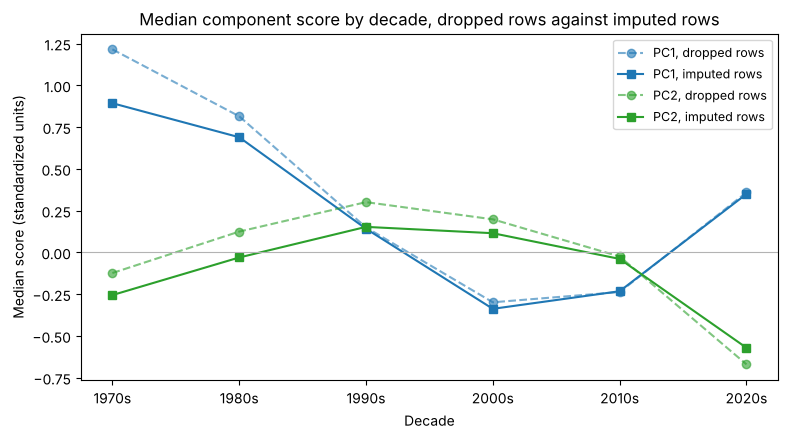

In [19]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Median PC1 and PC2 by decade as lines, both runs; reviewed and edited by Ansel Weng.
fig, ax = plt.subplots(figsize=(9, 4.5))
for pc, colour in [("PC1", "tab:blue"), ("PC2", "tab:green")]:
    ax.plot(centres_drop.index, centres_drop[pc], "o--", color=colour, alpha=0.6, label=f"{pc}, dropped rows")
    ax.plot(centres_imp.index, centres_imp[pc], "s-", color=colour, label=f"{pc}, imputed rows")
ax.axhline(0, color="0.7", linewidth=0.8)
ax.set_title("Median component score by decade, dropped rows against imputed rows")
ax.set_xlabel("Decade")
ax.set_ylabel("Median score (standardized units)")
ax.legend(fontsize=9)
save("12_decade_centres_compare.png")
plt.show()

**Takeaway:** the decade path keeps the shape notebook 03 found. PC1 still falls from the 1970s to a low in the 2000s (-0.34) and 2010s (-0.23) and turns back up in the 2020s (0.35); the 2020s is still the only decade with a median PC2 below -0.3 (-0.57 against -0.67). What changes is the **older decades**: the 1970s median moves from 1.22 to 0.89 on PC1 and the 1980s from 0.81 to 0.69, and the 1970s to 1990s medians sit 0.1 to 0.15 lower on PC2. The 2000s, 2010s and 2020s move by 0.1 or less on either axis.

The third column shows the shift comes from the rows, not from the new axes: on notebook 03's own components the imputed rows give nearly the same medians (1970s 0.85, 1980s 0.62). The complete games sit exactly where they did in notebook 03, so the change is due to the games added back, but part of where those games sit comes from values the imputer filled in. Section 7a below checks how much. The spread of decade medians therefore shrinks, from 1.52 to 1.23 on PC1 and from 0.97 to 0.72 on PC2, but PC1 remains the axis along which decades differ most.

### 7a. Is the shift the added games themselves, or the values filled in for them?

Two checks. (1) The attributes the added 1970s and 1980s games actually report, with no filled values, against the complete games of the same decade. (2) The decade medians on notebook 03's axes when the gaps are filled with the complete games' median instead of k-NN: if the early decades still move, the shift does not depend on how the gaps are filled.

In [20]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-11. Checks for the claim that the early-decade shift comes from the games added back: their observed attributes, and a median fill instead of k-NN; reviewed and edited by Ansel Weng.
added = ~scope["complete"]
observed_only = []
for d in ["1970s", "1980s"]:
    in_d = decade == d
    for col in ["minplaytime", "maxplaytime", "minage", "n_mechanics"]:
        observed_only.append({"decade": d, "attribute": col,
                              "complete games, median": scope.loc[in_d & ~added, col].median(),
                              "added games, median of observed values": scope.loc[in_d & added, col].median(),
                              "added games with it observed": f"{scope.loc[in_d & added, col].notna().sum()} of {(in_d & added).sum()}"})
display(pd.DataFrame(observed_only))

X_median_fill = X_obs.fillna(X_obs[scope["complete"]].median())
Z_median_fill = pd.DataFrame(drop["scaler"].transform(X_median_fill), columns=X_obs.columns, index=X_obs.index)
on_drop_axes_median = pd.DataFrame(drop["pca"].transform(Z_median_fill), columns=pc_names, index=X_obs.index)
pd.concat({"dropped (notebook 03)": centres_drop,
           "added games only, k-NN fill": on_drop_axes[added].groupby(decade[added])[["PC1", "PC2"]].median(),
           "all games, k-NN fill": centres_fixed,
           "all games, median fill": on_drop_axes_median.groupby(decade)[["PC1", "PC2"]].median()}, axis=1).round(2)


,decade,attribute,"complete games, median","added games, median of observed values",added games with it observed
0,1970s,minplaytime,90.0,30.0,98 of 113
1,1970s,maxplaytime,90.0,30.0,98 of 113
2,1970s,minage,12.0,8.0,66 of 113
3,1970s,n_mechanics,3.0,2.0,57 of 113
4,1980s,minplaytime,60.0,45.0,148 of 179
5,1980s,maxplaytime,90.0,45.0,148 of 179
6,1980s,minage,12.0,10.0,119 of 179
7,1980s,n_mechanics,2.0,2.0,90 of 179


dropped (notebook 03)       added games only, k-NN fill        \
                         PC1   PC2                         PC1   PC2   
decade                                                                 
1970s                   1.22 -0.12                       -0.65 -0.15   
1980s                   0.81  0.12                       -0.26  0.22   
1990s                   0.15  0.30                       -0.23  0.29   
2000s                  -0.30  0.20                       -0.72  0.07   
2010s                  -0.24 -0.02                       -0.67 -0.09   
2020s                   0.36 -0.67                       -0.21 -0.35   

       all games, k-NN fill       all games, median fill        
                        PC1   PC2                    PC1   PC2  
decade                                                          
1970s                  0.85 -0.13                   0.81 -0.14  
1980s                  0.62  0.13                   0.58  0.12  
1990s                  0.09  0.30                   0.05  0.28  
2000s                 -0.40  0.17                  -0.39  0.17  
2010s                 -0.30 -0.03                  -0.30 -0.03  
2020s                  0.28 -0.60                   0.28 -0.61

**Takeaway: the shift is mostly the added games themselves, not the fill.** On their observed values alone, the added 1970s games are shorter (median 30 against 90 minutes, known for 98 of 113) and for younger players (minimum age 8 against 12, known for 66 of 113); the added 1980s games are shorter too (45 against 90 minutes maximum) and for younger players (10 against 12). Filling the gaps with a plain median instead of k-NN moves the 1970s median on notebook 03's axes to 0.81 (k-NN: 0.85) and the 1980s to 0.58 (0.62), so the early decades move towards the centre whichever fill is used. The claim is limited in two ways: the number of mechanics, one of PC1's attributes, is missing for about half the added early games (56 of 113 in the 1970s), so their position on it is the imputer's; and the 113 and 179 added games are small groups.

In [21]:
# [AI-assisted] Claude Code (Opus 5.5), 2026-11-10. Median of each attribute by decade in its original units, dropped rows against imputed rows; reviewed and edited by Ansel Weng.
# Filled values are averages of five neighbours, so an imputed game can have, say, 2.4 mechanics; medians can therefore fall between whole numbers.
imp_units = X_imp.copy()
for col in log_cols:
    imp_units["log10_" + col] = 10 ** imp_units["log10_" + col]
imp_units.columns = attrs
med = pd.concat({"dropped": scope[scope["complete"]].groupby("decade")[attrs].median(),
                 "imputed": imp_units.groupby(decade)[attrs].median()}, axis=1).swaplevel(axis=1)[attrs]
med.round(1)

minplayers         maxplayers         minplaytime         maxplaytime  \
          dropped imputed    dropped imputed     dropped imputed     dropped   
decade                                                                         
1970s         2.0     2.0        2.0     3.0        90.0    90.0        90.0   
1980s         2.0     2.0        4.0     4.0        60.0    60.0        90.0   
1990s         2.0     2.0        4.0     4.0        60.0    60.0        60.0   
2000s         2.0     2.0        4.0     4.0        45.0    40.0        45.0   
2010s         2.0     2.0        4.0     4.0        30.0    30.0        45.0   
2020s         2.0     2.0        4.0     4.0        30.0    30.0        60.0   

                minage         n_mechanics         n_categories          
       imputed dropped imputed     dropped imputed      dropped imputed  
decade                                                                   
1970s     90.0    12.0    12.0         3.0     3.0          2.0     2.0  
1980s     63.2    12.0    11.4         2.0     2.0          2.0     2.0  
1990s     60.0    10.0    10.0         2.0     2.0          2.0     2.0  
2000s     45.0    10.0    10.0         2.0     2.0          2.0     2.0  
2010s     45.0    10.0    10.0         3.0     3.0          3.0     2.2  
2020s     60.0    12.0    10.0         4.0     4.0          3.0     2.4

**Takeaway:** in the original units, most decade medians are identical with and without imputation. The differences: maximum play time in the 1980s (90 dropped against 63 imputed minutes), minimum age in the 1980s (12 against 11.4) and the 2020s (12 against 10), the number of categories in the 2010s (3 against 2.2) and 2020s (3 against 2.4), maximum players in the 1970s (2 against 3), and minimum play time in the 2000s (45 against 40). The fractional values come from filled-in games, whose attributes are the averages of five neighbours.

## 8. What changes when the dropped games are imputed instead

**The PCA's structure does not change.** The variance table (70.7% from three components against 70.5%), the loadings (every PC1 loading within 0.01) and the correlations between attributes (within 0.02) are all essentially notebook 03's. The components keep their names: PC1 is play time, minimum age and number of mechanics; PC2 is player counts; PC3 is the number of categories and mechanics.

**The decade comparison changes in degree, not direction.** The early decades (1970s, 1980s) sit closer to the centre on PC1 once their incomplete games are added back, and the decade medians span a smaller range on both components. The ordering and the turn in the 2020s are unchanged.

For the descriptive question, the answer from notebook 03 holds on all 20,928 kept games: differences between decades move mainly along PC1, which mixes play time and minimum age with the number of mechanics, and much less along player counts (PC2), apart from the 2020s. Dropping incomplete games slightly exaggerated how different the 1970s and 1980s were.

## 9. Notes on reading this notebook

- Imputer: `KNNImputer(n_neighbors=5)`, the same setting notebook 05 tested, run on standardized log-scale attributes plus `yearpublished`, and fitted on all 20,928 kept rows; there is no test set in a descriptive analysis. Year is used only to find neighbours and is not a PCA attribute.
- Rows follow notebook 05's rule: the 195 games with no publication year are left out (as in notebook 03, they cannot be placed in a decade), and so are the 55 games from the 1970s on that are missing 4 or more of the 8 inputs. An earlier version of this notebook kept those 55; dropping them moves no eigenvalue, loading or decade median on the components by more than 0.03.
- The k-NN fill creates 43 games whose minimum play time is above their maximum (47 with the 4 already in the raw data; section 2). They are kept, since 0.2% of rows cannot move the PCA, but they would need fixing before the filled values were used game by game.
- Imputed counts are not rounded to whole numbers; the PCA works on standardized values, so rounding would only add noise.
- The sign of a component is arbitrary; imputed components would be flipped to match notebook 03 where their loadings pointed the other way, and none needed it here.
- Figures are saved to `figures/` with the prefix `12_`.